# DSE 511 Capstone — Lane B: Memoryless ML

**Goal:** Train two memoryless models that predict `accel_mps2` using the features such as the current `gap_m`, `speed_mps`, and `closing_speed_mps`:

1. Linear Regression
2. Gradient Boosting Regressor

## 1. Imports and configuration

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from joblib import parallel_config
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make the shared `carfollow` package importable from anywhere inside the repo.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "carfollow").is_dir())
sys.path.insert(0, str(REPO_ROOT))

from carfollow import IDM, KeepSpeed, check_model, load_table, split_by_group
from carfollow.baselines import MAX_BRAKE_MPS2
from carfollow.kinematics import advance
from carfollow.schema import DT, HISTORY_FEATURES, HISTORY_STEPS
from lanes.B_memoryless.memoryless import (
    FEATURE_BUILDERS, PHYSICS_FEATURES, PHYSICS_MONOTONIC, MemorylessAccelerationModel,
    load_model, physics_features, save_model,
)

RANDOM_STATE = 511
FEATURES = list(HISTORY_FEATURES)  # gap_m, speed_mps, closing_speed_mps
TARGET = "accel_mps2"
GROUP_COL = "driver_group"
ROLLOUT_STEPS = 300     # 30 s at 0.1 s

CSV_PATH = REPO_ROOT / "data" / "sample" / "pairs_full.csv"
DATA_TAG = CSV_PATH.stem.removeprefix("pairs_")   # "full" or "sample"; used in output file names
print(f"Using data file: {CSV_PATH}  (tag: {DATA_TAG})")

Using data file: /Users/mdjubairpantho/dse511-car-following/data/sample/pairs_full.csv  (tag: full)


## 2. Load and inspect the data

In [2]:
df = load_table(CSV_PATH)

print("Shape:", df.shape)
display(df.head())

print("\nRows per driver group:")
display(df.groupby(GROUP_COL).size().rename("rows").to_frame())

print("Unique drivers:", df["driver_id"].nunique(), "| pairs:", df["pair_id"].nunique())

leader_length = df["leader_position_m"] - df["position_m"] - df["gap_m"]
print(f"Leader length implied by the table: {leader_length.min():.2f} to {leader_length.max():.2f} m")
print(f"Largest change within one pair: {leader_length.groupby(df['pair_id']).std().max():.5f} m")

Shape: (3677482, 14)


,pair_id,driver_id,leader_id,driver_group,global_time_ms,t_s,position_m,leader_position_m,gap_m,speed_mps,leader_speed_mps,closing_speed_mps,accel_mps2,leader_accel_mps2
0,1->3015@1118847869000,1,3015,4,1118847869000,0.0,34.4574,54.4350,16.7772,5.8910,8.9429,-3.0518,0.0055,0.6194
1,1->3015@1118847869000,1,3015,4,1118847869100,0.1,35.0465,55.3293,17.0824,5.8916,9.0048,-3.1132,0.0055,0.6012
2,1->3015@1118847869000,1,3015,4,1118847869200,0.2,35.6356,56.2297,17.3937,5.8922,9.0649,-3.1728,0.0055,0.6358
3,1->3015@1118847869000,1,3015,4,1118847869300,0.3,36.2249,57.1362,17.7110,5.8927,9.1285,-3.2358,0.0055,0.7077
4,1->3015@1118847869000,1,3015,4,1118847869400,0.4,36.8141,58.0491,18.0346,5.8933,9.1993,-3.3060,0.0055,0.8306



Rows per driver group:


,rows
driver_group,
0,735051
1,731922
2,742074
3,727981
4,740454


Unique drivers: 5995 | pairs: 8301
Leader length implied by the table: 1.68 to 23.20 m
Largest change within one pair: 0.00006 m


## 3. Physics features (memoryless)

Every feature is a function of the current `gap`, `speed` and `closing speed` only so the models remain memoryless.

| Feature | Meaning | Expected effect on acceleration |
|---|---|---|
| `gap_m` | space to the leader | + |
| `speed_mps` | own speed | − |
| `closing_speed_mps` | positive = getting closer | − |
| `inv_gap` | 1 / gap, grows fast at short gaps | − |
| `inv_headway` | speed / gap = 1 / time headway | − |
| `inv_ttc` | closing / gap = 1 / time-to-collision | − |
| `brake_need` | closing·\|closing\| / (2·gap): deceleration that matches the leader's speed before the gap closes | − |
| `idm_textbook` | what textbook IDM would do in this state | + |

In [3]:
# physics_features, PHYSICS_FEATURES and PHYSICS_MONOTONIC are defined in lanes/B_memoryless/memoryless.py,
# so the saved models carry the same feature code Lane D will load.
RAW_FEATURES = FEATURES
assert PHYSICS_FEATURES[:3] == FEATURES

physics_preview = pd.DataFrame(physics_features(df[FEATURES].to_numpy()), columns=PHYSICS_FEATURES)
display(physics_preview.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
gap_m,3677482.0,16.392,10.625,0.114,9.306,13.968,20.640,187.562
speed_mps,3677482.0,8.947,4.145,0.000,6.088,9.181,11.967,27.901
closing_speed_mps,3677482.0,-0.131,1.320,-11.908,-0.895,-0.087,0.610,12.601
inv_gap,3677482.0,0.092,0.086,0.005,0.048,0.072,0.107,8.749
inv_headway,3677482.0,0.634,0.371,0.000,0.405,0.570,0.788,98.089
inv_ttc,3677482.0,-0.007,0.117,-18.641,-0.060,-0.006,0.044,25.479
brake_need,3677482.0,-0.007,0.138,-34.835,-0.028,-0.000,0.014,37.099
idm_textbook,3677482.0,-0.668,1.908,-9.000,-1.112,-0.023,0.546,1.000


## 4. Define the models

Four Lane B variants, plus the two shared baselines for reference:

| Model | Features | Notes |
|---|---|---|
| Linear Regression (raw) | 3 raw | the original baseline |
| Linear Regression (physics) | 3 Raw + 5 derived features | **hand-off candidate** |
| Gradient Boosting (raw) | 3 raw | the original, unconstrained; fixed settings, not tuned |
| Gradient Boosting (physics, monotonic) | 3 Raw + 5 derived features | **hand-off candidate** |
| KeepSpeed, IDM textbook, IDM calibrated | — | Lane A baselines, not trained |

Each fitted estimator is wrapped in `MemorylessAccelerationModel`, which implements the plug. Its output is clipped to ±9 m/s² (the same braking limit IDM uses), so a linear model cannot ask for impossible accelerations far outside the training range.

In [4]:
# MemorylessAccelerationModel is defined in lanes/B_memoryless/memoryless.py.

def make_linear_regression():
    return LinearRegression()


def make_gradient_boosting(monotonic_cst=None):
    return HistGradientBoostingRegressor(
        max_iter=250,
        learning_rate=0.05,
        max_leaf_nodes=7,
        min_samples_leaf=200,
        l2_regularization=1.0,
        monotonic_cst=monotonic_cst,
        random_state=RANDOM_STATE,
    )


# name -> (feature set, estimator factory, tuned with inner GridSearchCV?)
LANE_B_MODELS = {
    "Linear Regression (raw)": ("raw", make_linear_regression, False),
    "Linear Regression (physics)": ("physics", make_linear_regression, False),
    "Gradient Boosting (raw)": ("raw", make_gradient_boosting, False),   # comparison only: fixed settings
    "Gradient Boosting (physics, monotonic)": ("physics", lambda: make_gradient_boosting(PHYSICS_MONOTONIC), True),
}

# Smaller grid, based on the earlier full run (18 settings, 10 searches):
#   learning_rate 0.04 won 8/10 -> fixed at 0.04
#   max_leaf_nodes 31 never won -> dropped
#   min_samples_leaf 200 (the largest value) won 10/10 -> also try 400 in case the best is higher
gb_param_grid = {
    "max_leaf_nodes": [25],
    "min_samples_leaf": [400],
}

N_OUTER, N_INNER = 5, 4
n_settings = len(gb_param_grid["max_leaf_nodes"]) * len(gb_param_grid["min_samples_leaf"])
n_tuned = sum(tune for _, _, tune in LANE_B_MODELS.values())
print(f"Grid-search fits: {n_settings} settings x {N_INNER} inner folds x {N_OUTER} outer folds x "
      f"{n_tuned} tuned model = {n_settings * N_INNER * N_OUTER * n_tuned} (was 720)")

Grid-search fits: 1 settings x 4 inner folds x 5 outer folds x 1 tuned model = 20 (was 720)


## 5. Local closed-loop rollout (Drive and Spread proxies)

In [5]:
def _batch_accel(model):
    if hasattr(model, "accel_batch"):
        return model.accel_batch
    return lambda histories: np.array([model.accel(h) for h in histories])


def advance_batch(position, speed, accel):
    # carfollow.kinematics.advance for many cars at once (its max() only takes scalars).
    return position + speed * DT, np.maximum(speed + accel * DT, 0.0)


# The batch rule must match the shared one exactly.
_rng = np.random.default_rng(RANDOM_STATE)
_p, _v, _a = _rng.uniform(0, 500, 1000), _rng.uniform(0, 35, 1000), _rng.uniform(-9, 9, 1000)
_batch_p, _batch_v = advance_batch(_p, _v, _a)
assert all((bp, bv) == advance(p, v, a) for bp, bv, p, v, a in zip(_batch_p, _batch_v, _p, _v, _a))


class KeepSpeedBatch(KeepSpeed):
    def accel_batch(self, histories):
        return np.zeros(len(histories))


class IDMBatch(IDM):
    # Same formula as carfollow.baselines.IDM.accel, for many histories at once.
    def accel_batch(self, histories):
        gap, v, dv = (np.asarray(histories, dtype=float)[:, -1, i] for i in range(3))
        s_star = self.s0 + np.maximum(0.0, v * self.T + v * dv / (2.0 * np.sqrt(self.a_max * self.b)))
        with np.errstate(divide="ignore", invalid="ignore"):
            a = self.a_max * (1.0 - (np.maximum(v, 0.0) / self.v0) ** self.delta - (s_star / gap) ** 2)
        return np.where(gap <= 0.0, -MAX_BRAKE_MPS2, np.maximum(a, -MAX_BRAKE_MPS2))


def rollout(model, drivers, steps=ROLLOUT_STEPS, replay=False):
    # replay=True feeds the real accelerations instead of the model (sanity check).
    pairs = [p.reset_index(drop=True) for _, p in drivers.groupby("pair_id", sort=True)]
    pairs = [p for p in pairs if len(p) > HISTORY_STEPS]
    n, start = len(pairs), HISTORY_STEPS - 1
    length = np.array([min(len(p) - HISTORY_STEPS, steps) for p in pairs])

    leader_pos = np.full((n, steps + 1), np.nan)
    leader_speed = np.full((n, steps + 1), np.nan)
    real_gap = np.full((n, steps + 1), np.nan)
    real_speed = np.full((n, steps + 1), np.nan)
    real_accel = np.full((n, steps + 1), np.nan)
    histories = np.empty((n, HISTORY_STEPS, 3))
    for j, p in enumerate(pairs):
        window = p.iloc[start : start + length[j] + 1]
        leader_pos[j, : len(window)] = window["leader_position_m"]
        leader_speed[j, : len(window)] = window["leader_speed_mps"]
        real_gap[j, : len(window)] = window["gap_m"]
        real_speed[j, : len(window)] = window["speed_mps"]
        real_accel[j, : len(window)] = window[TARGET]
        histories[j] = p.iloc[: start + 1][FEATURES].to_numpy()

    leader_length = np.array([p["leader_position_m"].iloc[start] - p["position_m"].iloc[start] - p["gap_m"].iloc[start] for p in pairs])
    position = np.array([p["position_m"].iloc[start] for p in pairs])
    speed = np.array([p["speed_mps"].iloc[start] for p in pairs])
    sim_gap = np.full((n, steps + 1), np.nan)
    sim_speed = np.full((n, steps + 1), np.nan)
    sim_gap[:, 0], sim_speed[:, 0] = real_gap[:, 0], speed
    alive = np.ones(n, dtype=bool)
    crashed = np.zeros(n, dtype=bool)
    accel_fn = None if replay else _batch_accel(model)

    for k in range(steps):
        active = alive & (k < length)
        if not active.any():
            break
        idx = np.flatnonzero(active)
        a = real_accel[idx, k] if replay else accel_fn(histories[idx])
        position[idx], speed[idx] = advance_batch(position[idx], speed[idx], a)

        gap = leader_pos[:, k + 1] - position - leader_length
        closing = speed - leader_speed[:, k + 1]
        sim_gap[active, k + 1] = gap[active]
        sim_speed[active, k + 1] = speed[active]
        histories[active] = np.concatenate(
            [histories[active, 1:], np.column_stack([gap, speed, closing])[active, None, :]], axis=1
        )
        hit = active & (gap <= 0.0)
        crashed |= hit
        alive &= ~hit

    sim, real = sim_gap[:, 1:], real_gap[:, 1:]
    both = np.isfinite(sim) & np.isfinite(real)
    sim_headway = sim[both] / sim_speed[:, 1:][both]
    real_headway = real[both] / real_speed[:, 1:][both]
    keep = (sim_speed[:, 1:][both] > 1.0) & (real_speed[:, 1:][both] > 1.0)
    return {
        "drive_gap_rmse": float(np.sqrt(np.mean((sim[both] - real[both]) ** 2))),
        "drive_crashes": int(crashed.sum()),
        "spread_w1": float(wasserstein_distance(sim_headway[keep], real_headway[keep])),
        "n_rollouts": n,
        "sim_gap": sim_gap,
        "real_gap": real_gap,
        "pair_ids": [p["pair_id"].iloc[0] for p in pairs],
    }


def rollout_check(model, drivers, n=20, seed=RANDOM_STATE):
    # The batch path must agree with the plug's single-history accel().
    rng = np.random.default_rng(seed)
    pairs = [p for _, p in drivers.groupby("pair_id") if len(p) > HISTORY_STEPS]
    for _ in range(n):
        p = pairs[rng.integers(len(pairs))]
        i = rng.integers(HISTORY_STEPS - 1, len(p))
        h = p.iloc[i - HISTORY_STEPS + 1 : i + 1][FEATURES].to_numpy()
        assert np.isclose(model.accel(h), _batch_accel(model)(h[None])[0])


# Sanity check: replaying the real accelerations must reproduce the real gaps exactly.
replay = rollout(None, df, replay=True)
print(f"Replay check over all pairs: gap RMSE = {replay['drive_gap_rmse']:.4f} m, crashes = {replay['drive_crashes']}")

/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]


Replay check over all pairs: gap RMSE = 0.0006 m, crashes = 0


## 6. Nested group cross-validation: Step and Drive on every held-out group

In [6]:
fold_rows = []
fold_models = {}
fold_searches = []
example_rollouts = {}

unique_groups = sorted(df[GROUP_COL].unique())
inner_splits = min(4, len(unique_groups) - 1)

for test_group in unique_groups:
    train_df, test_df = split_by_group(df, test_group=test_group)
    states_train = train_df[FEATURES].to_numpy()
    states_test = test_df[FEATURES].to_numpy()
    y_train = train_df[TARGET].to_numpy()
    y_test = test_df[TARGET].to_numpy()
    groups_train = train_df[GROUP_COL].to_numpy()
    print(f"Outer test group {test_group}: train rows={len(train_df):,}, test rows={len(test_df):,}")

    # Score only rows that every lane can predict: drop the first 29 rows of each pair
    # (no full 3 s history yet) and the last row (its acceleration can't be checked).
    pos = test_df.groupby("pair_id").cumcount()
    size = test_df.groupby("pair_id")["pair_id"].transform("size")
    score_mask = ((pos >= HISTORY_STEPS - 1) & (pos < size - 1)).to_numpy()
    y_score = y_test[score_mask]
    print(f"  scored rows={score_mask.sum():,}")

    candidates = {
        "KeepSpeed": KeepSpeedBatch(),
        "IDM textbook": IDMBatch(name="idm_textbook"),
        "IDM calibrated": IDMBatch.calibrated(),   # Lane A's shared calibrated set
    }

    for name, (feature_set, factory, tune) in LANE_B_MODELS.items():
        X_train = FEATURE_BUILDERS[feature_set](states_train)
        if tune:
            search = GridSearchCV(
                estimator=factory(),
                param_grid=gb_param_grid,
                scoring="neg_root_mean_squared_error",
                cv=GroupKFold(n_splits=inner_splits),
                n_jobs=-1,
                error_score="raise",
            )
            # One thread per worker: 8 workers x 8 boosting threads would fight over 8 cores.
            with parallel_config(backend="loky", inner_max_num_threads=1):
                search.fit(X_train, y_train, groups=groups_train)
            estimator = search.best_estimator_
            fold_searches.append({
                "model": name,
                "test_driver_group": test_group,
                "best_params": search.best_params_,
                "best_inner_cv_RMSE": -search.best_score_,
            })
        else:
            estimator = factory().fit(X_train, y_train)
        candidates[name] = MemorylessAccelerationModel(name, estimator, feature_set)

    for name, model in candidates.items():
        # Memoryless models only read history[-1], so a one-row history per test row is enough.
        pred = _batch_accel(model)(states_test[score_mask][:, None, :])
        drive = rollout(model, test_df)
        rollout_check(model, test_df)
        fold_rows.append({
            "model": name,
            "test_driver_group": test_group,
            "n_test": len(y_score),
            "MAE (m/s^2)": mean_absolute_error(y_score, pred),
            "RMSE (m/s^2)": mean_squared_error(y_score, pred) ** 0.5,
            "R2": r2_score(y_score, pred),
            "drive_gap_rmse (m)": drive["drive_gap_rmse"],
            "drive_crashes": drive["drive_crashes"],
            "n_rollouts": drive["n_rollouts"],
            "spread_w1 (s)": drive["spread_w1"],
        })
        fold_models[(name, test_group)] = model
        if test_group == unique_groups[0]:
            example_rollouts[name] = drive

fold_results = pd.DataFrame(fold_rows)
display(fold_results.round(4))

grid_search_summary = pd.DataFrame(fold_searches)
print("Gradient Boosting settings selected inside each outer training fold:")
display(grid_search_summary)

Outer test group 0: train rows=2,942,431, test rows=735,051
  scored rows=685,851


/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_

Outer test group 1: train rows=2,945,560, test rows=731,922
  scored rows=681,732


/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_

Outer test group 2: train rows=2,935,408, test rows=742,074
  scored rows=691,854


/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_

... (3 outputs left out)

/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:88: RuntimeWarning: divide by zero encountered in divide
  real_headway = real[both] / real_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_57095/2844335840.py:87: RuntimeWarning: divide by zero encountered in divide
  sim_headway = sim[both] / sim_speed[:, 1:][both]
/var/folders/83/lhj8l74s56v3dtltspxxzkj80000gn/T/ipykernel_

,model,test_driver_group,n_test,MAE (m/s^2),RMSE (m/s^2),R2,drive_gap_rmse (m),drive_crashes,n_rollouts,spread_w1 (s)
0,KeepSpeed,0,685851,0.5377,0.7420,-0.0055,31.2561,676,1640,2.6912
1,IDM textbook,0,685851,1.1993,1.9778,-6.1437,6.5492,0,1640,0.4637
2,IDM calibrated,0,685851,0.5741,0.7634,-0.0642,9.1048,0,1640,0.4836
3,Linear Regression (raw),0,685851,0.4837,0.6497,0.2292,7.0371,400,1640,0.1182
4,Linear Regression (physics),0,685851,0.4778,0.6365,0.2602,6.6645,28,1640,0.0755
5,Gradient Boosting (raw),0,685851,0.4649,0.6219,0.2937,6.3243,145,1640,0.0726
6,"Gradient Boosting (physics, monotonic)",0,685851,0.4693,0.6257,0.2850,6.2959,80,1640,0.0867
7,KeepSpeed,1,681732,0.5402,0.7429,-0.0057,30.8415,708,1673,2.8283
8,IDM textbook,1,681732,1.1580,1.8980,-5.5634,6.7978,0,1673,0.4905
9,IDM calibrated,1,681732,0.5807,0.7735,-0.0901,9.4055,0,1673,0.5039


Gradient Boosting settings selected inside each outer training fold:


,model,test_driver_group,best_params,best_inner_cv_RMSE
0,"Gradient Boosting (physics, monotonic)",0,"{'max_leaf_nodes': 25, 'min_samples_leaf': 400}",0.626801
1,"Gradient Boosting (physics, monotonic)",1,"{'max_leaf_nodes': 25, 'min_samples_leaf': 400}",0.625944
2,"Gradient Boosting (physics, monotonic)",2,"{'max_leaf_nodes': 25, 'min_samples_leaf': 400}",0.627287
3,"Gradient Boosting (physics, monotonic)",3,"{'max_leaf_nodes': 25, 'min_samples_leaf': 400}",0.626945
4,"Gradient Boosting (physics, monotonic)",4,"{'max_leaf_nodes': 25, 'min_samples_leaf': 400}",0.627164


## 7. Summary across the five held-out groups

In [7]:
MODEL_ORDER = ["KeepSpeed", "IDM textbook", "IDM calibrated", *LANE_B_MODELS]

summary = (
    fold_results.groupby("model")
    .agg(
        MAE_mean=("MAE (m/s^2)", "mean"),
        RMSE_mean=("RMSE (m/s^2)", "mean"),
        RMSE_sd=("RMSE (m/s^2)", "std"),
        R2_mean=("R2", "mean"),
        drive_gap_rmse_mean=("drive_gap_rmse (m)", "mean"),
        drive_gap_rmse_sd=("drive_gap_rmse (m)", "std"),
        crashes_total=("drive_crashes", "sum"),
        rollouts_total=("n_rollouts", "sum"),
        spread_w1_mean=("spread_w1 (s)", "mean"),
    )
    .reindex(MODEL_ORDER)
    .reset_index()
)
display(summary.round(4))

,model,MAE_mean,RMSE_mean,RMSE_sd,R2_mean,drive_gap_rmse_mean,drive_gap_rmse_sd,crashes_total,rollouts_total,spread_w1_mean
0,KeepSpeed,0.5377,0.7401,0.0023,-0.0059,31.3821,0.3812,3437,8301,2.9086
1,IDM textbook,1.1646,1.9169,0.0438,-5.7505,6.6684,0.1374,0,8301,0.4702
2,IDM calibrated,0.5762,0.7668,0.0070,-0.0799,9.2323,0.3008,0,8301,0.4962
3,Linear Regression (raw),0.4849,0.6501,0.0024,0.2240,6.8913,0.0966,2020,8301,0.1116
4,Linear Regression (physics),0.4787,0.6367,0.0019,0.2556,6.5696,0.1051,155,8301,0.0860
5,Gradient Boosting (raw),0.4660,0.6222,0.0020,0.2890,6.3018,0.1242,664,8301,0.0835
6,"Gradient Boosting (physics, monotonic)",0.4704,0.6261,0.0021,0.2801,6.2491,0.1256,399,8301,0.1011


In [8]:
## Group 0 only: the shared test group, for comparing with the other lanes
SHARED_TEST_GROUP = 0

group0 = (
    fold_results[fold_results["test_driver_group"] == SHARED_TEST_GROUP]
    .set_index("model")
    .reindex(MODEL_ORDER)
    .drop(columns="test_driver_group")
    .reset_index()
)
display(group0.round(4))


,model,n_test,MAE (m/s^2),RMSE (m/s^2),R2,drive_gap_rmse (m),drive_crashes,n_rollouts,spread_w1 (s)
0,KeepSpeed,685851,0.5377,0.7420,-0.0055,31.2561,676,1640,2.6912
1,IDM textbook,685851,1.1993,1.9778,-6.1437,6.5492,0,1640,0.4637
2,IDM calibrated,685851,0.5741,0.7634,-0.0642,9.1048,0,1640,0.4836
3,Linear Regression (raw),685851,0.4837,0.6497,0.2292,7.0371,400,1640,0.1182
4,Linear Regression (physics),685851,0.4778,0.6365,0.2602,6.6645,28,1640,0.0755
5,Gradient Boosting (raw),685851,0.4649,0.6219,0.2937,6.3243,145,1640,0.0726
6,"Gradient Boosting (physics, monotonic)",685851,0.4693,0.6257,0.2850,6.2959,80,1640,0.0867


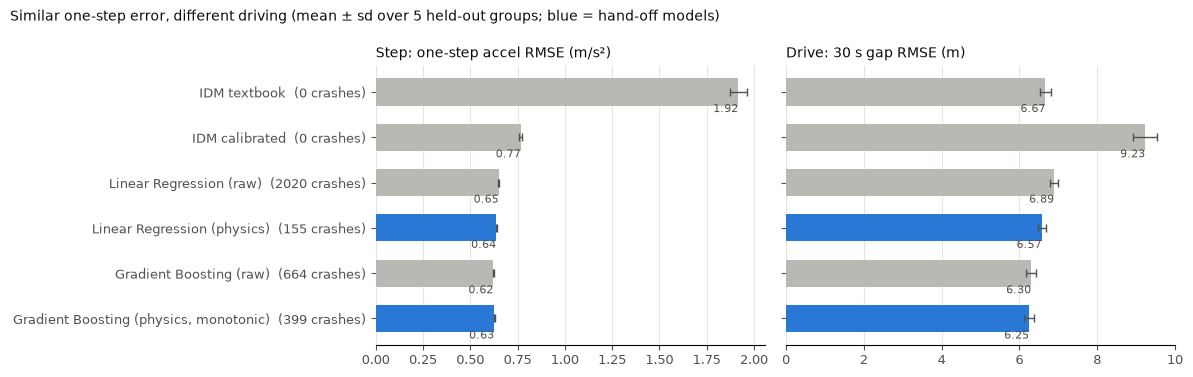

In [9]:
# Two measures with different units -> two panels, one axis each.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
HIGHLIGHT, BASE = "#2a78d6", "#b9b8b2"
handoff = {"Linear Regression (physics)", "Gradient Boosting (physics, monotonic)"}

plot_df = summary.set_index("model").drop(index="KeepSpeed")  # KeepSpeed's drive error dwarfs the rest
colors = [HIGHLIGHT if m in handoff else BASE for m in plot_df.index]
panels = [
    ("RMSE_mean", "RMSE_sd", "Step: one-step accel RMSE (m/s²)"),
    ("drive_gap_rmse_mean", "drive_gap_rmse_sd", "Drive: 30 s gap RMSE (m)"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (col, sd, title) in zip(axes, panels):
    y = np.arange(len(plot_df))
    ax.barh(y, plot_df[col], xerr=plot_df[sd], color=colors, height=0.6,
            error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 3})
    for yi, value in zip(y, plot_df[col]):
        ax.text(value, yi + 0.38, f"{value:.2f}", va="center", ha="right", fontsize=8, color=MUTED)
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)
axes[0].set_yticks(np.arange(len(plot_df)), [
    f"{m}  ({int(c)} crash{'' if c == 1 else 'es'})" for m, c in zip(plot_df.index, plot_df["crashes_total"])
])
axes[0].invert_yaxis()
fig.suptitle("Similar one-step error, different driving (mean ± sd over 5 held-out groups; blue = hand-off models)",
             x=0.01, ha="left", fontsize=10, color=INK)
plt.tight_layout()
plt.show()

## 8. One rollout up close

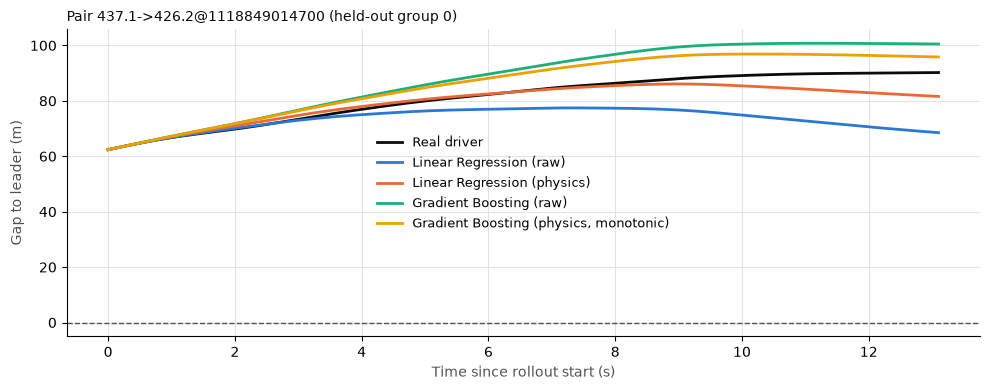

In [10]:
TRACE_MODELS = list(LANE_B_MODELS)
TRACE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order

# Pick the pair whose simulated gaps disagree most across models (a crash leaves NaN after it).
import warnings

gaps = np.stack([example_rollouts[m]["sim_gap"] for m in TRACE_MODELS])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)  # steps after every rollout ended are all NaN
    disagreement = np.nan_to_num(np.nanmax(gaps, axis=0) - np.nanmin(gaps, axis=0), nan=-1.0)
j = int(np.argmax(disagreement.max(axis=1)))
t = np.arange(ROLLOUT_STEPS + 1) * 0.1

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, example_rollouts[TRACE_MODELS[0]]["real_gap"][j], color=INK, linewidth=2, label="Real driver")
for name, color in zip(TRACE_MODELS, TRACE_COLORS):
    ax.plot(t, example_rollouts[name]["sim_gap"][j], color=color, linewidth=2, label=name)
ax.axhline(0, color=MUTED, linewidth=1, linestyle="--")
ax.set_xlabel("Time since rollout start (s)", color=MUTED)
ax.set_ylabel("Gap to leader (m)", color=MUTED)
ax.set_title(f"Pair {example_rollouts[TRACE_MODELS[0]]['pair_ids'][j]} (held-out group {unique_groups[0]})",
             loc="left", fontsize=10, color=INK)
ax.grid(color=GRID, linewidth=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 9. Final hand-off models and the `accel(history)` plug

The hand-off models are **Linear Regression (physics)** and **Gradient Boosting (physics, monotonic)**. They are refit on all available rows for Lane D's simulator. Do **not** report scores from these refits; the held-out numbers are in section 7.

Gradient Boosting uses the parameter set chosen most often across the outer folds. Both pass the shared `check_model`.

Each file in `outputs/` holds the **whole plug**, so Lane D loads it and calls `accel(history)` directly:

```python
from lanes.B_memoryless.memoryless import load_model
model = load_model("lanes/B_memoryless/outputs/gradient_boosting_physics_full.joblib")
model.accel(history)   # history: (30, 3)
```

In [11]:
from collections import Counter

output_dir = REPO_ROOT / "lanes" / "B_memoryless" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

fold_results.to_csv(output_dir / "lane_b_fold_results.csv", index=False)
summary.to_csv(output_dir / "lane_b_summary.csv", index=False)
grid_search_summary.to_csv(output_dir / "lane_b_grid_search_by_outer_fold.csv", index=False)

GB_NAME = "Gradient Boosting (physics, monotonic)"
final_gb_params = dict(Counter(
    tuple(sorted(row["best_params"].items()))
    for row in fold_searches if row["model"] == GB_NAME
).most_common(1)[0][0])
print("Final Gradient Boosting parameters:", final_gb_params)

X_all = physics_features(df[FEATURES].to_numpy())
y_all = df[TARGET].to_numpy()
lane_b_models = {
    "linear_regression": MemorylessAccelerationModel(
        "lane_b_linear_regression", make_linear_regression().fit(X_all, y_all), "physics"
    ),
    "gradient_boosting": MemorylessAccelerationModel(
        "lane_b_gradient_boosting",
        make_gradient_boosting(PHYSICS_MONOTONIC).set_params(**final_gb_params).fit(X_all, y_all),
        "physics",
    ),
}

example_history = np.tile(df[FEATURES].iloc[-1].to_numpy(dtype=float), (HISTORY_STEPS, 1))
for key, model in lane_b_models.items():
    check_model(model)
    # Save the whole plug (wrapper + estimator), so Lane D can call accel(history) directly.
    path = output_dir / f"{key}_physics_{DATA_TAG}.joblib"
    save_model(model, path)
    # Hand-off check: the reloaded file must pass the plug and give the same answer.
    reloaded = load_model(path)
    check_model(reloaded)
    assert reloaded.accel(example_history) == model.accel(example_history)
    print(f"{model.name}: passes check_model after reload; accel(example) = "
          f"{reloaded.accel(example_history):.4f} m/s²  ->  {path.name}")

print(f"Saved outputs to: {output_dir}")

Final Gradient Boosting parameters: {'max_leaf_nodes': 25, 'min_samples_leaf': 400}
lane_b_linear_regression: passes check_model after reload; accel(example) = -0.3266 m/s²  ->  linear_regression_physics_full.joblib
lane_b_gradient_boosting: passes check_model after reload; accel(example) = -0.2006 m/s²  ->  gradient_boosting_physics_full.joblib
Saved outputs to: /Users/mdjubairpantho/dse511-car-following/lanes/B_memoryless/outputs
